Tester le modèle final sur un dataset BTC plus court
pour voir si ses performances restent cohérentes.

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

In [2]:
RAW_PATH = Path("../data/raw")
FINAL_PATH = Path("../data/final")
MODEL_PATH = Path("../models")

In [3]:
df_short = pd.read_csv(
    RAW_PATH / "BTCUSD_2018-01-01_2025-12-31_raw.csv"
)

df_short.head()

,symbol,date,open,high,low,close,volume,change,changePercent,vwap
0,BTCUSD,2025-12-31,88397.24,89100.00,87082.64,87497.94,33830210616,-899.30,-1.017340,88019.4550
1,BTCUSD,2025-12-30,87110.77,89343.52,86704.98,88397.50,35586356225,1286.73,1.477120,87889.1925
2,BTCUSD,2025-12-29,87877.28,90325.00,86675.00,87110.78,48411625849,-766.50,-0.872240,87997.0150
3,BTCUSD,2025-12-28,87806.75,88000.00,87349.52,87877.29,15156557929,70.54,0.080336,87758.3900
4,BTCUSD,2025-12-27,87296.17,87914.62,86944.24,87808.00,13741199310,511.83,0.586310,87490.7575


In [4]:
def clean_data(df):

    df = df.copy()

    df["date"] = pd.to_datetime(df["date"])

    df = (
        df.sort_values("date")
          .reset_index(drop=True)
    )

    df = df.drop_duplicates()

    numeric_cols = [
        "open",
        "high",
        "low",
        "close",
        "volume",
        "change",
        "changePercent",
        "vwap"
    ]

    for col in numeric_cols:

        if col in df.columns:

            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )

    return df

In [5]:
df_short_clean = clean_data(df_short)

df_short_clean.head()

,symbol,date,open,high,low,close,volume,change,changePercent,vwap
0,BTCUSD,2021-05-22,37333.09,38889.76,35257.52,37476.83,57377273240,143.74,0.38502,37239.3000
1,BTCUSD,2021-05-23,37476.84,38319.36,31111.00,34758.67,78469274361,-2718.17,-7.25293,35416.4675
2,BTCUSD,2021-05-24,34758.88,39966.87,34407.17,38878.56,67359584098,4119.68,11.85217,37002.8700
3,BTCUSD,2021-05-25,38874.53,39878.51,36481.26,38361.81,56211915803,-512.72,-1.31891,38399.0275
4,BTCUSD,2021-05-26,38361.81,40900.00,37837.36,39293.23,51346735160,931.42,2.42799,39098.1000


In [6]:
def add_features(df):

    df = df.copy()

    df["return"] = df["close"].pct_change()
    df["return_1"] = df["close"].pct_change(1)
    df["return_3"] = df["close"].pct_change(3)
    df["return_7"] = df["close"].pct_change(7)

    df["volatility_5"] = df["return"].rolling(5).std()
    df["volatility_20"] = df["return"].rolling(20).std()

    df["sma_20"] = df["close"].rolling(20).mean()

    df["ema_20"] = df["close"].ewm(
        span=20,
        adjust=False
    ).mean()

    df["dist_sma"] = (
        (df["close"] - df["sma_20"]) /
        df["sma_20"]
    )

    df["dist_ema"] = (
        (df["close"] - df["ema_20"]) /
        df["ema_20"]
    )

    delta = df["close"].diff()

    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.rolling(14).mean()
    avg_loss = loss.rolling(14).mean()

    rs = avg_gain / avg_loss

    df["rsi"] = 100 - (100 / (1 + rs))

    rolling_std = df["close"].rolling(20).std()

    df["BB_middle"] = df["sma_20"]
    df["BB_upper"] = df["BB_middle"] + 2 * rolling_std
    df["BB_lower"] = df["BB_middle"] - 2 * rolling_std

    df["BB_width"] = (
        (df["BB_upper"] - df["BB_lower"]) /
        df["BB_middle"]
    )

    df["BB_percent"] = (
        (df["close"] - df["BB_lower"]) /
        (df["BB_upper"] - df["BB_lower"])
    )

    df["trend_signal"] = np.where(
        df["ema_20"] > df["sma_20"],
        1,
        0
    )

    df["return_acceleration"] = df["return"].diff()

    return df

In [7]:
df_short_features = add_features(df_short_clean)

df_short_features.head()

,symbol,date,open,high,low,close,volume,change,changePercent,vwap,...,dist_sma,dist_ema,rsi,BB_middle,BB_upper,BB_lower,BB_width,BB_percent,trend_signal,return_acceleration
0,BTCUSD,2021-05-22,37333.09,38889.76,35257.52,37476.83,57377273240,143.74,0.38502,37239.3000,...,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
1,BTCUSD,2021-05-23,37476.84,38319.36,31111.00,34758.67,78469274361,-2718.17,-7.25293,35416.4675,...,NaN,-0.066078,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
2,BTCUSD,2021-05-24,34758.88,39966.87,34407.17,38878.56,67359584098,4119.68,11.85217,37002.8700,...,NaN,0.040198,NaN,NaN,NaN,NaN,NaN,NaN,0,0.191057
3,BTCUSD,2021-05-25,38874.53,39878.51,36481.26,38361.81,56211915803,-512.72,-1.31891,38399.0275,...,NaN,0.023801,NaN,NaN,NaN,NaN,NaN,NaN,0,-0.131820
4,BTCUSD,2021-05-26,38361.81,40900.00,37837.36,39293.23,51346735160,931.42,2.42799,39098.1000,...,NaN,0.043822,NaN,NaN,NaN,NaN,NaN,NaN,0,0.037571


In [8]:
def create_target(df):

    df = df.copy()

    df["future_return_5"] = (
        df["close"].shift(-5) /
        df["close"]
    ) - 1

    conditions = [
        df["future_return_5"] > df["volatility_20"],
        df["future_return_5"] < -df["volatility_20"]
    ]

    choices = [1, -1]

    df["target"] = np.select(
        conditions,
        choices,
        default=0
    )

    df = df.dropna().reset_index(drop=True)

    return df

In [9]:
df_short_target = create_target(df_short_features)

df_short_target["target"].value_counts(normalize=True)

target
 0    0.424096
 1    0.305422
-1    0.270482
Name: proportion, dtype: float64

In [10]:
final_features = joblib.load(
    MODEL_PATH / "final_features.pkl"
)

final_features

['close',
 'volume',
 'changePercent',
 'vwap',
 'return',
 'return_1',
 'return_3',
 'return_7',
 'volatility_5',
 'volatility_20',
 'sma_20',
 'ema_20',
 'dist_sma',
 'dist_ema',
 'rsi',
 'BB_upper',
 'BB_lower',
 'BB_width',
 'BB_percent',
 'trend_signal',
 'return_acceleration']

In [11]:
df_short_final = df_short_target[
    final_features + ["target"]
].copy()

df_short_final.to_csv(
    FINAL_PATH / "BTCUSD_short_final_dataset.csv",
    index=False
)

df_short_final.head()

,close,volume,changePercent,vwap,return,return_1,return_3,return_7,volatility_5,volatility_20,...,dist_sma,dist_ema,rsi,BB_upper,BB_lower,BB_width,BB_percent,trend_signal,return_acceleration,target
0,37338.44,38699736985,1.75373,36918.0875,0.017561,0.017561,0.117846,0.013076,0.067801,0.054557,...,0.018467,0.021256,54.460187,40189.838447,33133.014553,0.192486,0.595937,0,0.036538,0
1,35557.33,37924228550,-4.77436,36245.2200,-0.047702,-0.047702,-0.049367,0.000502,0.064159,0.053053,...,-0.031171,-0.024909,52.406213,40156.414851,33246.304149,0.188279,0.334441,0,-0.065263,1
2,39015.24,40669112838,9.72492,37187.2825,0.097249,0.097249,0.063258,0.089797,0.072653,0.050767,...,0.062848,0.062840,57.698191,40181.871738,33234.515262,0.189259,0.832075,1,0.144951,-1
3,40539.47,43148914673,3.90676,39843.8925,0.039068,0.039068,0.085730,0.207398,0.055693,0.051318,...,0.101105,0.093494,57.530824,40629.044201,33005.108799,0.207076,0.988251,1,-0.058181,-1
4,40162.37,46420149185,-0.92644,40383.4575,-0.009302,-0.009302,0.129510,0.202389,0.054261,0.051168,...,0.089576,0.074793,58.113993,40808.740196,32912.326804,0.214224,0.918144,1,-0.048370,-1


In [12]:
model = joblib.load(
    MODEL_PATH / "gradient_boosting_final.pkl"
)

scaler = joblib.load(
    MODEL_PATH / "scaler_final.pkl"
)

config = joblib.load(
    MODEL_PATH / "final_config.pkl"
)

buy_th = config["buy_threshold"]
sell_th = config["sell_threshold"]

In [13]:
def predict_with_threshold(model, X_scaled, buy_th, sell_th):

    y_proba = model.predict_proba(X_scaled)

    classes = model.classes_

    idx_sell = list(classes).index(-1)
    idx_buy = list(classes).index(1)

    y_pred = []

    for proba in y_proba:

        if proba[idx_buy] >= buy_th:
            y_pred.append(1)

        elif proba[idx_sell] >= sell_th:
            y_pred.append(-1)

        else:
            y_pred.append(0)

    return np.array(y_pred)

In [14]:
X_short = df_short_final[final_features]
y_short = df_short_final["target"]

X_short_scaled = scaler.transform(X_short)

y_pred_short = predict_with_threshold(
    model,
    X_short_scaled,
    buy_th,
    sell_th
)

In [15]:
print(confusion_matrix(y_short, y_pred_short))

print(
    classification_report(
        y_short,
        y_pred_short,
        zero_division=0
    )
)

[[199 168  82]
 [183 401 120]
 [145 224 138]]
              precision    recall  f1-score   support

          -1       0.38      0.44      0.41       449
           0       0.51      0.57      0.54       704
           1       0.41      0.27      0.33       507

    accuracy                           0.44      1660
   macro avg       0.43      0.43      0.42      1660
weighted avg       0.44      0.44      0.44      1660



In [16]:

df_long = pd.read_csv(
    FINAL_PATH / "BTCUSD_final_dataset.csv"
)

X_long = df_long[final_features]
y_long = df_long["target"]

In [17]:
split = int(len(df_long) * 0.8)

X_long_test = X_long.iloc[split:]
y_long_test = y_long.iloc[split:]

In [18]:
X_long_test_scaled = scaler.transform(
    X_long_test
)

In [19]:
y_pred_long = predict_with_threshold(
    model,
    X_long_test_scaled,
    buy_th,
    sell_th
)

In [20]:
comparison = pd.DataFrame([

    {
        "Dataset":"BTC long (test only)",

        "Accuracy":accuracy_score(
            y_long_test,
            y_pred_long
        ),

        "F1_BUY":f1_score(
            y_long_test,
            y_pred_long,
            labels=[1],
            average="macro",
            zero_division=0
        ),

        "F1_SELL":f1_score(
            y_long_test,
            y_pred_long,
            labels=[-1],
            average="macro",
            zero_division=0
        ),

        "F1_macro":f1_score(
            y_long_test,
            y_pred_long,
            average="macro",
            zero_division=0
        )
    },

    {
        "Dataset":"BTC court",

        "Accuracy":accuracy_score(
            y_short,
            y_pred_short
        ),

        "F1_BUY":f1_score(
            y_short,
            y_pred_short,
            labels=[1],
            average="macro",
            zero_division=0
        ),

        "F1_SELL":f1_score(
            y_short,
            y_pred_short,
            labels=[-1],
            average="macro",
            zero_division=0
        ),

        "F1_macro":f1_score(
            y_short,
            y_pred_short,
            average="macro",
            zero_division=0
        )
    }

])

comparison

,Dataset,Accuracy,F1_BUY,F1_SELL,F1_macro
0,BTC long (test only),0.358794,0.278481,0.354793,0.352013
1,BTC court,0.444578,0.325856,0.407787,0.423127


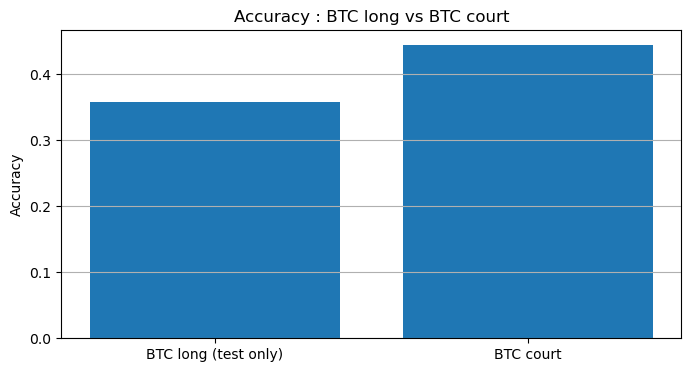

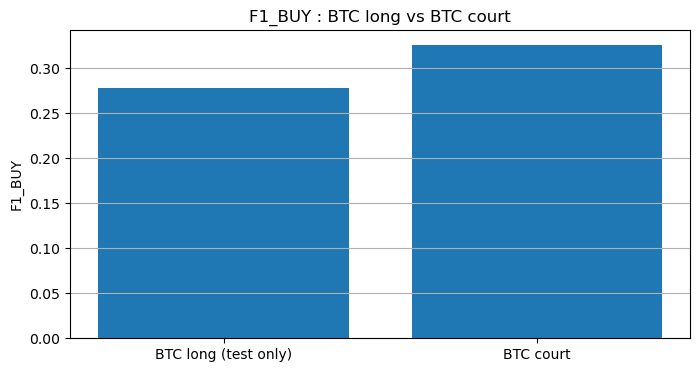

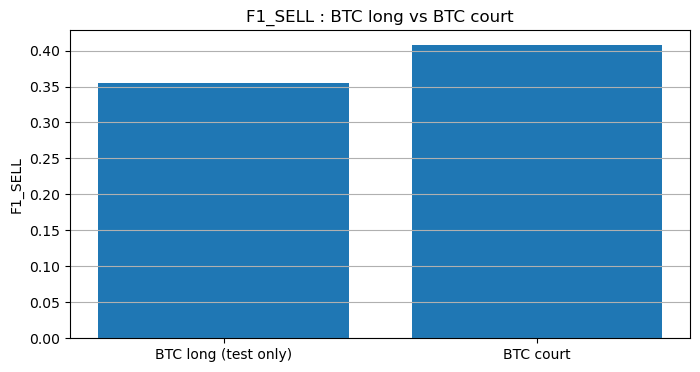

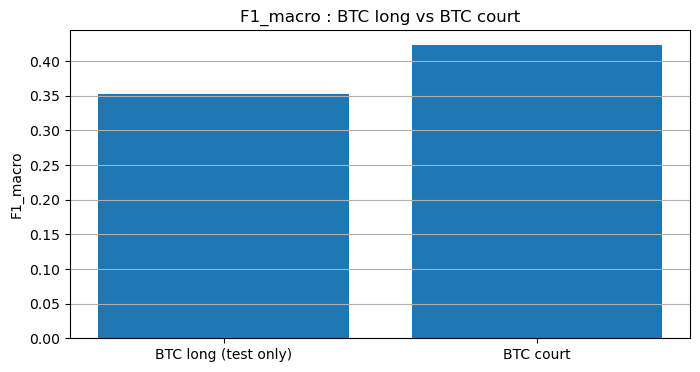

In [21]:
metrics = [
    "Accuracy",
    "F1_BUY",
    "F1_SELL",
    "F1_macro"
]

for metric in metrics:

    plt.figure(figsize=(8,4))

    plt.bar(
        comparison["Dataset"],
        comparison[metric]
    )

    plt.title(
        f"{metric} : BTC long vs BTC court"
    )

    plt.ylabel(metric)

    plt.grid(axis="y")

    plt.show()

Le modèle a été évalué sur deux jeux de données distincts :

- une partie test du dataset historique BTC (jamais vue pendant l'entraînement)
- une période BTC plus récente

L'objectif était de mesurer sa capacité à généraliser sur des données non observées.

Les résultats obtenus montrent :

- Accuracy : 0.359 → 0.445
- F1_macro : 0.352 → 0.423

Le signal SELL reste relativement stable :

- F1_SELL : 0.355 → 0.408

Le signal BUY reste plus difficile à détecter :

- F1_BUY : 0.278 → 0.326

Ces résultats suggèrent que la prédiction des mouvements haussiers est plus complexe que celle des mouvements baissiers dans notre contexte.

Ils indiquent également que le modèle ne capture pas uniquement des patterns historiques spécifiques, mais conserve une certaine capacité de généralisation.

Cependant, les performances globales restent modérées, ce qui montre que le comportement du marché Bitcoin évolue au cours du temps et que le modèle reste sensible aux changements de régime de marché.

In [22]:
# Variables les plus influentes du modéle

importances = pd.Series(
    model.feature_importances_,
    index=final_features
)

importances = importances.sort_values(
    ascending=False
)

importances

volatility_20          0.163231
BB_percent             0.110037
BB_lower               0.101092
BB_width               0.073772
volume                 0.070987
BB_upper               0.067709
rsi                    0.066540
sma_20                 0.048749
volatility_5           0.045198
dist_ema               0.042336
ema_20                 0.039914
vwap                   0.033505
close                  0.029705
dist_sma               0.027136
return_7               0.022130
return_3               0.017748
return_acceleration    0.016374
return                 0.008865
return_1               0.006237
changePercent          0.005870
trend_signal           0.002862
dtype: float64

In [23]:
top_features = importances.head(15)

top_features

volatility_20    0.163231
BB_percent       0.110037
BB_lower         0.101092
BB_width         0.073772
volume           0.070987
BB_upper         0.067709
rsi              0.066540
sma_20           0.048749
volatility_5     0.045198
dist_ema         0.042336
ema_20           0.039914
vwap             0.033505
close            0.029705
dist_sma         0.027136
return_7         0.022130
dtype: float64

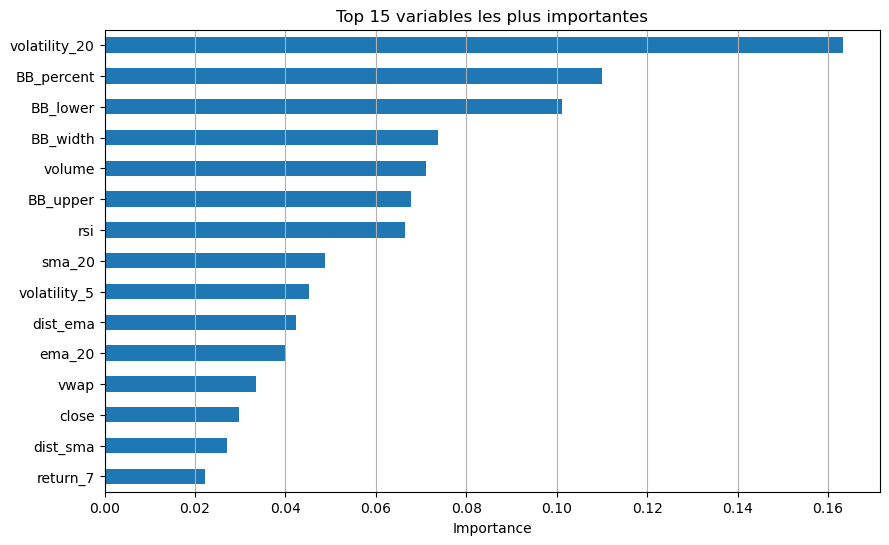

In [24]:
plt.figure(figsize=(10,6))

top_features.sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 15 variables les plus importantes"
)

plt.xlabel(
    "Importance"
)

plt.grid(
    axis="x"
)

plt.show()

In [25]:
importance_df = pd.DataFrame({

    "Variable": importances.index,

    "Importance": importances.values

})

importance_df["Importance_%"] = (
    importance_df["Importance"]
    /
    importance_df["Importance"].sum()
)*100

importance_df.head(15)

,Variable,Importance,Importance_%
0,volatility_20,0.163231,16.323146
1,BB_percent,0.110037,11.003737
2,BB_lower,0.101092,10.109192
3,BB_width,0.073772,7.377239
4,volume,0.070987,7.098718
5,BB_upper,0.067709,6.770885
6,rsi,0.066540,6.654012
7,sma_20,0.048749,4.874942
8,volatility_5,0.045198,4.519804
9,dist_ema,0.042336,4.233566


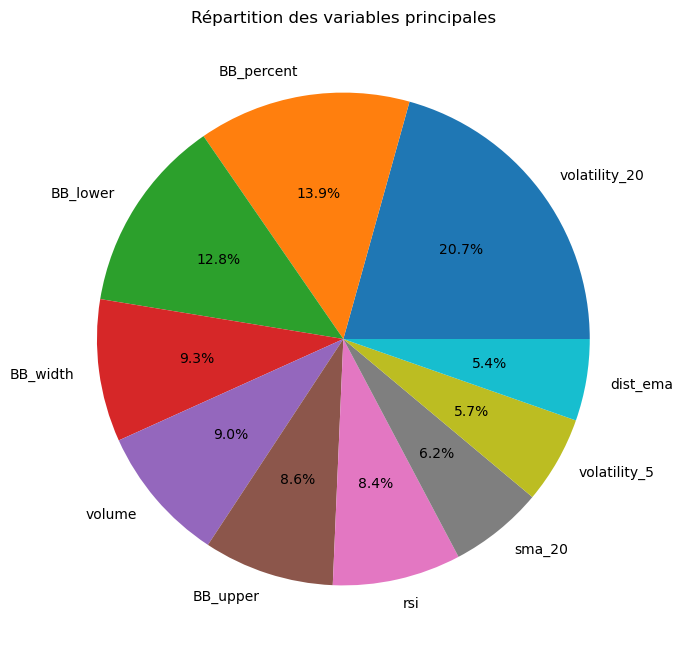

In [26]:
top10 = importance_df.head(10)

plt.figure(figsize=(8,8))

plt.pie(
    top10["Importance_%"],
    labels=top10["Variable"],
    autopct="%1.1f%%"
)

plt.title(
    "Répartition des variables principales"
)

plt.show()

L'analyse des importances montre que le modèle est fortement influencé par les mesures de volatilité et les Bandes de Bollinger.

Les variables associées aux Bandes de Bollinger représentent près de 45 % de l'importance totale.

Cela suggère que le modèle détecte principalement les positions relatives du prix dans son environnement de fluctuation plutôt qu'une simple dynamique de prix.

Cette forte dépendance pourrait également expliquer la baisse des performances sur une période BTC plus récente.

En effet, les relations historiques entre ces indicateurs et les mouvements haussiers peuvent évoluer au cours du temps.

In [27]:
family_dict = {

    "Momentum / Rendement":[
        "return_1",
        "return_3",
        "return_7",
        "rsi"
    ],

    "Volatilité":[
        "volatility_5",
        "volatility_20"
    ],

    "Tendance":[
        "sma_20",
        "dist_ema"
    ],

    "Bandes Bollinger":[
        "BB_upper",
        "BB_lower",
        "BB_width",
        "BB_percent"
    ],

    "Volume":[
        "volume"
    ]
}

In [28]:
family_importance = {}

for family, variables in family_dict.items():

    total_importance = 0

    for var in variables:

        if var in importances.index:

            total_importance += importances[var]

    family_importance[family] = total_importance

In [29]:
family_df = pd.DataFrame({

    "Famille":family_importance.keys(),
    "Importance":family_importance.values()

})

family_df["Importance_%"]=(

    family_df["Importance"]
    /
    family_df["Importance"].sum()

)*100

family_df

,Famille,Importance,Importance_%
0,Momentum / Rendement,0.112655,13.479250
1,Volatilité,0.208429,24.938695
2,Tendance,0.091085,10.898376
3,Bandes Bollinger,0.352611,42.190029
4,Volume,0.070987,8.493652


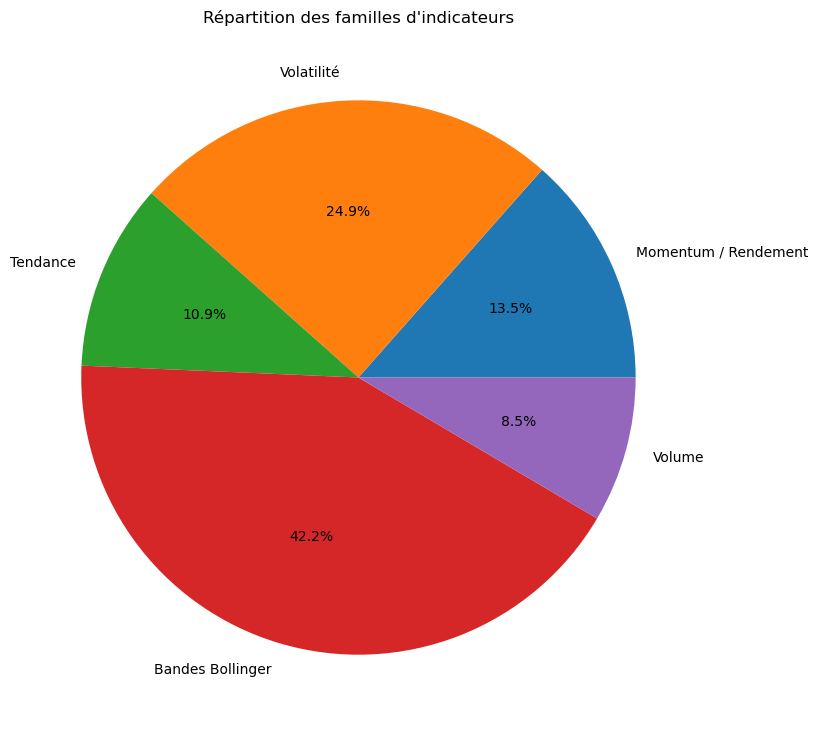

In [30]:
plt.figure(figsize=(9,9))

plt.pie(
    family_df["Importance_%"],
    labels=family_df["Famille"],
    autopct="%1.1f%%"
)

plt.title(
    "Répartition des familles d'indicateurs"
)

plt.show()

L'analyse des familles d'indicateurs montre que le modèle s'appuie principalement sur les Bandes de Bollinger (42.2 %) et les indicateurs de volatilité (24.9 %).

Les signaux générés semblent donc davantage dépendre du régime de marché et du positionnement relatif du prix dans son environnement de fluctuation que d'une logique purement directionnelle basée sur la tendance.

Le momentum, la tendance et le volume jouent un rôle complémentaire mais moins déterminant.

Ces résultats permettent également d'expliquer certaines variations observées lors des tests sur des périodes plus récentes : les relations historiques entre volatilité, bandes de Bollinger et mouvements haussiers peuvent évoluer dans le temps.

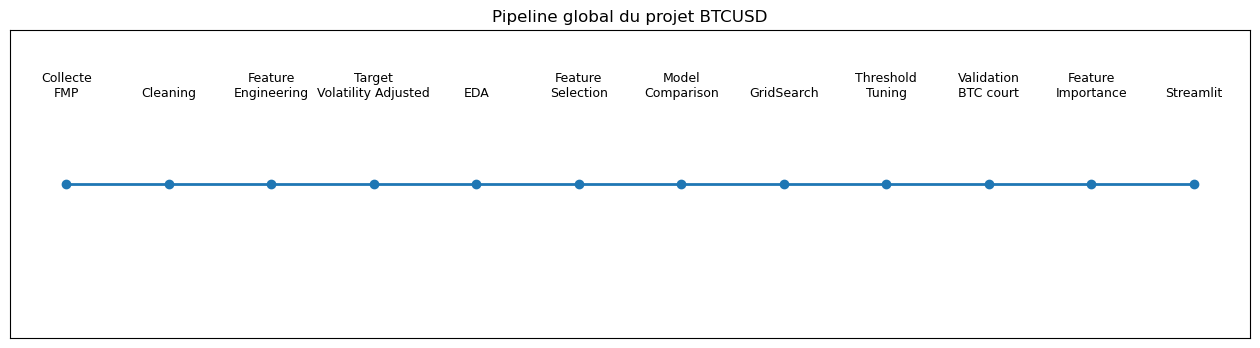

In [31]:
import matplotlib.pyplot as plt

steps = [
    "Collecte\nFMP",
    "Cleaning",
    "Feature\nEngineering",
    "Target\nVolatility Adjusted",
    "EDA",
    "Feature\nSelection",
    "Model\nComparison",
    "GridSearch",
    "Threshold\nTuning",
    "Validation\nBTC court",
    "Feature\nImportance",
    "Streamlit"
]

y = [1] * len(steps)

plt.figure(figsize=(16, 4))

plt.plot(
    range(len(steps)),
    y,
    marker="o",
    linewidth=2
)

for i, step in enumerate(steps):
    plt.text(
        i,
        1.03,
        step,
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.yticks([])
plt.xticks([])
plt.title("Pipeline global du projet BTCUSD")
plt.grid(axis="x", alpha=0.3)
plt.show()

## Synthèse du raisonnement

Le projet suit une démarche complète de Data Science :

1. collecte et nettoyage des données ;
2. création d'indicateurs techniques ;
3. construction d'une target dynamique ajustée à la volatilité ;
4. analyse exploratoire ;
5. sélection des variables ;
6. comparaison et optimisation des modèles ;
7. ajustement du seuil de décision ;
8. validation sur une période BTC plus courte ;
9. interprétation des variables importantes ;
10. déploiement dans une application Streamlit.

Cette démarche permet de passer d'une donnée financière brute à un système interprétable de génération de signaux BUY / HOLD / SELL.